In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)

import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

import numpy as np
from tqdm import tqdm
import datetime

from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil
import matplotlib.pyplot as plt

import utils.functions as fc
import utils.util_deep_learning as udl
import utils.util as util



Forma de la matriz de Gram: (4, 64, 64)


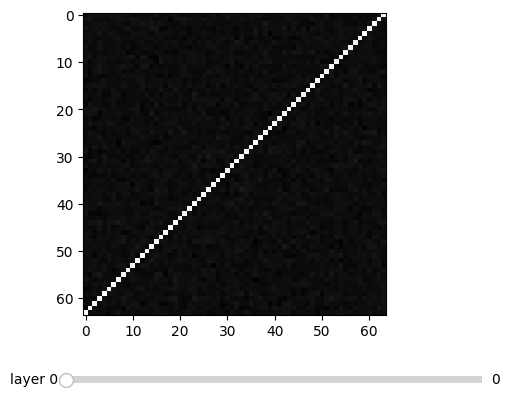

In [2]:

def gram_matrix(feature_maps):
    # Obtener las dimensiones de los mapas de características
    batch_size, height, width, channels = tf.shape(feature_maps)
    
    # Reshape los mapas de características para que cada fila represente un vector de características
    reshaped_feature_maps = tf.reshape(feature_maps, (batch_size, height * width, channels))
    
    # Calcular la matriz de Gram
    gram_matrix = tf.matmul(reshaped_feature_maps, reshaped_feature_maps, transpose_a=True)
    
    # Normalizar la matriz de Gram
    num_elements = tf.cast(height * width * channels, tf.float32)
    gram_matrix /= num_elements
    
    return gram_matrix

# Ejemplo de uso
# Supongamos que tienes un tensor de mapas de características de una capa convolucional de una CNN
# feature_maps tiene la forma (batch_size, height, width, channels)
batch_size = 4
height = 64
width = 64
channels = 64
feature_maps = tf.random.normal((batch_size, height, width, channels))

# Calcular la matriz de Gram
gram_matrix_result = gram_matrix(feature_maps)

# Imprimir la forma de la matriz de Gram resultante
print("Forma de la matriz de Gram:", gram_matrix_result.shape)
fc.imgshow_3D("", gram_matrix_result, mooving_plane=0, current_plane=0)


Forma del Gram Matrix: (4, 64, 64)


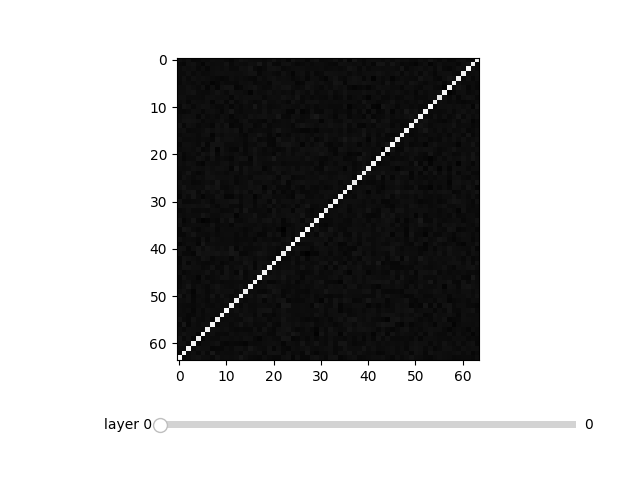

tf.Tensor(
[[ 1.6062161e-02 -3.2057421e-04 -6.8217705e-05 ... -1.2025818e-04
  -2.7455782e-04  1.0426301e-04]
 [-3.2057421e-04  1.5699856e-02 -1.0049281e-04 ...  1.7918291e-04
  -3.7378931e-04 -7.3809133e-05]
 [-6.8217705e-05 -1.0049281e-04  1.5569852e-02 ... -2.4051851e-06
   1.7311679e-04  1.3951752e-04]
 ...
 [-1.2025818e-04  1.7918291e-04 -2.4051851e-06 ...  1.5743254e-02
   2.2758942e-04 -7.8811143e-05]
 [-2.7455782e-04 -3.7378931e-04  1.7311679e-04 ...  2.2758942e-04
   1.5366081e-02 -2.4758963e-04]
 [ 1.0426301e-04 -7.3809133e-05  1.3951752e-04 ... -7.8811143e-05
  -2.4758963e-04  1.5123135e-02]], shape=(64, 64), dtype=float32)


In [3]:
def gram_matrix(input_tensor):
    # Obtener las dimensiones del tensor de entrada
    batch_size, width, height, deep, channels = input_tensor.get_shape().as_list()

    # Redimensionar el tensor de entrada para aplanarlo
    reshaped_tensor = tf.reshape(input_tensor, [batch_size, width * height, deep])

    # Calcular el producto interno para cada pareja de vectores de características
    gram_matrix = tf.matmul(reshaped_tensor, reshaped_tensor, transpose_a=True)
    
    # Normalizar el Gram Matrix dividiendo por el número total de elementos
    num_elements = tf.cast(width * height * deep * channels, tf.float32)
    gram_matrix /= num_elements

    return gram_matrix

# def gram_matrix2(A):
#     gm_list = []
#     for i in range(0, A.shape[0]):
#         A_reshaped = tf.reshape(A[i], [A[i].shape[0], -1])
#         gm_list.append(tf.matmul(A_reshaped, A_reshaped, transpose_a=True))
#     # Assuming gm_list is a list of tensors
#     gm_list_stacked = tf.stack(gm_list, axis=0)
#     return gm_list_stacked

# Ejemplo de uso
# Definir un tensor de entrada de tamaño (batch_size, width, height, deep, channels)
batch_size = 4
width = 64
height = 64
deep = 64
channels = 1
input_tensor = tf.random.normal(shape=(batch_size, width, height, deep, channels))

# Calcular el Gram Matrix del tensor de entrada
gram_matrix_result = gram_matrix(input_tensor)

# Imprimir la forma del Gram Matrix resultante
%matplotlib widget

print("Forma del Gram Matrix:", gram_matrix_result.shape)
fc.imgshow_3D("", gram_matrix_result, mooving_plane=0, current_plane=0)
print(gram_matrix_result[0])

In [4]:
# Definir las dimensiones de las matrices
m = 64
n = 64
p = 64
q = 64

# Crear matrices A y B con valores aleatorios
A = np.random.rand(m, n, p)
B = np.random.rand(n, p, q)

# Realizar la multiplicación de matrices en tres dimensiones
C_np = np.tensordot(A, B, axes=([1, 2], [0, 1]))
C = tf.tensordot(A, B, axes=([1, 2], [0, 1]))


# Mostrar el resultado
print(f"Matriz A: {A.shape}")
print(A)
print(f"\nMatriz B: {B.shape}")
print(B)
print(f"\nResultado de la multiplicación: {C.shape}")
print(C)



Matriz A: (64, 64, 64)
[[[0.77448641 0.30859317 0.04375733 ... 0.81234325 0.32370021 0.99495799]
  [0.3933273  0.54818032 0.08032181 ... 0.89007686 0.93979553 0.41478895]
  [0.91502023 0.00745319 0.42940182 ... 0.02049599 0.77057563 0.2159876 ]
  ...
  [0.30952077 0.61237361 0.17353886 ... 0.20288213 0.16765547 0.72841907]
  [0.05765392 0.97998726 0.52092632 ... 0.15873299 0.98835744 0.79187747]
  [0.21917479 0.1311533  0.37460059 ... 0.93504028 0.66274193 0.0249476 ]]

 [[0.5387054  0.38511523 0.05081894 ... 0.38407286 0.63390674 0.9934118 ]
  [0.96360077 0.91551845 0.50420323 ... 0.39428119 0.34139772 0.0317526 ]
  [0.93934706 0.56397292 0.48849234 ... 0.24555877 0.78732108 0.14088716]
  ...
  [0.26304673 0.87156686 0.7413989  ... 0.21410023 0.45325528 0.60755669]
  [0.74814869 0.84940678 0.39739875 ... 0.40334291 0.85133832 0.55947639]
  [0.88624528 0.20133049 0.52583341 ... 0.81949976 0.10869769 0.48985367]]

 [[0.48299854 0.11560722 0.2100826  ... 0.82841842 0.93497955 0.62150636]